# 04 · Baselines, Tuning and Cost

**What this notebook does.** It builds the **yardstick** the deep-learning model must beat, tunes it fairly, and runs the tests that decide how **cheap** the final model can be. It reads only the files saved by notebook 03: no feature is recomputed here.

**Produces:** `Datasets/processed/baseline_oof.csv.gz` (every baseline's out-of-fold prediction on the rows the network will be scored on) and `baseline_card.json` (tuned settings, metrics, cost).

### Ground rules (same as notebook 03)
1. **Every decision carries an argument**: mechanism → evidence (a paired comparison with its 95% interval) → parsimony.
2. **The shipped model is deep learning only.** Baselines are **yardsticks**: they exist so that the network's result means something. They are never part of the prediction path.
3. **Test (Nov–Dec) is sealed.** Everything here uses Jan–Oct and rolling-origin folds.
4. **Cost is a result, not an afterthought**: rows needed, columns needed, seconds, parameters.

### Result in brief (from the run below)

| | Result |
|---|---|
| **Yardstick** | **tuned XGBoost**: AP 0.380 pooled over Jun–Oct. Logistic regression 0.348, prior 0.232. XGBoost beats logistic regression by **+0.031 (+0.020 to +0.047)** |
| Does tuning help? | **Not measurably**: +0.0002 AP (−0.0011 to +0.0016). It makes the model cheaper: **5.0 s instead of 8.6 s** to train (−42%) |
| More data? | AP rises about +0.005 per doubling of rows, and every smaller fraction is measurably worse: no free saving on rows |
| Fewer inputs? | The first six groups match the full set. **Destination adds no measurable AP** but is 27% of the illustrative network's parameters |
| Operating point | A fixed 35% precision target **breaks across seasons**: recall at that precision is 0.96 in June and 0.00 in September. State the target as lift over the month's base rate, or use calibrated probabilities with costs |
| Saved for later | `baseline_oof.csv.gz` and `baseline_card.json`, so the network is compared with the yardstick on identical rows |


### How to run
1. Run notebook 03 first: it writes `Datasets/processed/`, which this notebook reads. Put this notebook in the same `Notebooks/` folder.
2. Needs `xgboost` (`pip install xgboost`; Colab already has it), plus pandas, numpy, scikit-learn and matplotlib. About 5 minutes on one CPU; set `QUICK = True` for a short dry run.

## Architecture

```text
Datasets/processed/ (written by notebook 03)
      │  DatasetStore ............ reads the saved files; nothing is recomputed
      ▼
design_matrix ................... one-hot category ids (sizes from the spec) + the z-scored numbers
      │
BASELINES (factories) ........... prior · logistic regression · XGBoost
      │
out_of_fold harness ............. rolling origin: every row is scored by a model that never saw it
      │
metrics + paired day-block bootstrap ... 95% intervals on every comparison
      │
cost meter ...................... seconds, rows, columns, parameters
      │
baseline_oof.csv.gz + baseline_card.json   ← the yardstick, saved for the final comparison
```

| Principle | Where it shows up |
|---|---|
| **S**ingle responsibility | the reader reads · `design_matrix` shapes · factories build models · the harness validates · the cost meter times |
| **O**pen/closed | a new baseline is one more factory in `BASELINES`; nothing else changes |
| **L**iskov | every factory returns something with `fit` and `predict_proba`, so they are interchangeable |
| **I**nterface segregation | the harness needs a factory, not a library |
| **D**ependency inversion | the harness depends on that abstraction, not on XGBoost |

## Part A · The code
Small layers, one cell each. Part B only uses them.

In [6]:
import json, pickle, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, brier_score_loss, precision_recall_curve, roc_auc_score
from xgboost import XGBClassifier
warnings.filterwarnings("ignore")

### A1 · reader
Opens the folder written by notebook 03. It reads; it never recomputes a feature.

In [7]:
class DatasetStore:
    def __init__(self, folder):
        self.folder = Path(folder)
        assert (self.folder / "feature_spec.json").exists(), "Run notebook 03 first: Datasets/processed/ is missing."

    def spec(self) -> dict:
        with open(self.folder / "feature_spec.json") as f:
            return json.load(f)

    def load_split(self, name: str, groups=None):
        """(X, y, meta) for 'train', 'val' or 'test'. X holds the columns of `groups` (default: the recommended ones)."""
        spec = self.spec()
        columns = [c for g in (groups or spec["recommended_groups"]) for c in spec["groups"][g]]
        frame = pd.read_csv(self.folder / f"dl_{name}.csv.gz", parse_dates=["date"])
        return frame[columns], frame["y"].astype(int), frame[[c for c in spec["meta_columns"] if c != "y"]]

    def load_development(self, groups=None):
        """Train + val stacked (Jan-Oct). Test is never included."""
        parts = [self.load_split(name, groups) for name in ("train", "val")]
        return tuple(pd.concat(part, ignore_index=True) for part in zip(*parts))

    def save_baselines(self, oof: pd.DataFrame, card: dict) -> None:
        oof.to_csv(self.folder / "baseline_oof.csv.gz", index=False, float_format="%.6g")
        with open(self.folder / "baseline_card.json", "w") as f:
            json.dump(card, f, indent=2)

### A2 · design matrix
One-hot for the category ids (the vocabulary sizes come from the saved spec), plus the z-scored numbers. Dense `float32`.

In [8]:
def design_matrix(X: pd.DataFrame, spec: dict) -> np.ndarray:
    parts = []
    for col in X.columns:
        if col.endswith("_idx"):
            size = spec["categorical"][col[:-4]]["vocab_size"]
            parts.append(np.eye(size, dtype=np.float32)[X[col].to_numpy()])
        else:
            parts.append(X[[col]].to_numpy(np.float32))
    return np.hstack(parts)

### A3 · evidence tools
Rolling-origin folds, the paired day-block bootstrap, the decision rule and the metrics. Same ideas as notebook 03, re-defined here so this notebook stands alone.

In [9]:
def rolling_origin_folds(months, validation_months) -> list:
    """[(train_mask, val_mask), ...]: for each month m, train on every EARLIER month, validate on m."""
    months = np.asarray(months)
    return [(months < m, months == m) for m in validation_months]


def weighted_average_precision(y, p, weight=None):
    return average_precision_score(y, p, sample_weight=weight)


def recall_at_precision(y, p, target, weight=None) -> float:
    """Highest recall reachable while precision stays at or above `target` (0 if the target is unreachable)."""
    precision, recall, _ = precision_recall_curve(y, p, sample_weight=weight)
    ok = precision >= target
    return float(recall[ok].max()) if ok.any() else 0.0


def day_bootstrap(y, predictions: dict, days, n_boot: int, seed: int, metric=weighted_average_precision):
    """A metric of every prediction vector on the SAME resampled days (paired). Flights on one day share weather,
    so whole DAYS are resampled, not rows. Returns (point estimates, {name: array of n_boot resampled scores})."""
    keep = np.all([~np.isnan(p) for p in predictions.values()], axis=0)
    y, days = np.asarray(y)[keep], np.asarray(days)[keep]
    preds = {name: np.asarray(p)[keep] for name, p in predictions.items()}
    day_id, n_days = pd.factorize(days)[0], len(pd.unique(days))
    rng = np.random.default_rng(seed)
    draws = {name: np.empty(n_boot) for name in preds}
    for b in range(n_boot):
        weight = np.bincount(rng.integers(0, n_days, n_days), minlength=n_days)[day_id]
        used = weight > 0
        for name, p in preds.items():
            draws[name][b] = metric(y[used], p[used], weight[used])
    return {name: metric(y, p, None) for name, p in preds.items()}, draws


def compare_to_baseline(point: dict, draws: dict, baseline: str) -> pd.DataFrame:
    """Each variant against the baseline: difference in the metric and its 95% interval."""
    rows = []
    for name, d in draws.items():
        lo, hi = np.percentile(d - draws[baseline], [2.5, 97.5])
        rows.append({"variant": name, "metric": point[name], "delta": point[name] - point[baseline], "ci_low": lo, "ci_high": hi})
    return pd.DataFrame(rows)


def ece(y, p, bins: int = 10) -> float:
    """Expected calibration error: average gap between predicted and observed rate over probability bins."""
    y, p = np.asarray(y), np.asarray(p)
    which = np.digitize(p, np.linspace(0, 1, bins + 1)[1:-1])
    return float(sum((which == b).mean() * abs(y[which == b].mean() - p[which == b].mean())
                     for b in range(bins) if (which == b).any()))


def summarise(y, predictions: dict, precision_target: float) -> pd.DataFrame:
    """One row per model: ranking, the stated operating point, and calibration. Rows never validated are ignored."""
    keep = np.all([~np.isnan(p) for p in predictions.values()], axis=0)
    rows = {}
    for name, p in predictions.items():
        yk, pk = np.asarray(y)[keep], np.asarray(p)[keep]
        rows[name] = {"AP": average_precision_score(yk, pk), "ROC_AUC": roc_auc_score(yk, pk),
                      f"recall@precision>={precision_target:.0%}": recall_at_precision(yk, pk, precision_target),
                      "mean_predicted": pk.mean(), "observed_rate": yk.mean(), "ECE": ece(yk, pk), "Brier": brier_score_loss(yk, pk)}
    return pd.DataFrame(rows).T

### A4 · baselines (factories)
Each factory returns something with `fit` and `predict_proba`. Adding a baseline means adding one entry to `BASELINES`.

In [10]:
SEED = 42
# Starting settings, similar to Phase 1's XGBoost. Decision E tunes them.
XGB_START = dict(n_estimators=300, max_depth=5, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
                 min_child_weight=1, reg_lambda=1.0)

def prior_baseline():                      # always predicts the training base rate: the floor
    return DummyClassifier(strategy="prior")

def logistic_baseline():                   # linear, L2
    return LogisticRegression(max_iter=500)

def xgboost_baseline(**settings):          # the brief's boosting baseline
    return XGBClassifier(**{**XGB_START, **settings}, tree_method="hist", n_jobs=-1, random_state=SEED, eval_metric="logloss")

BASELINES = {"prior": prior_baseline, "logistic regression": logistic_baseline,
             "xgboost (starting settings)": xgboost_baseline}

### A5 · harness and cost meter
The harness depends only on a factory. `train_fraction` lets a fold train on a random share of its rows, which is how Decisions D and E save cost.

In [11]:
def out_of_fold(make_model, X, y, months, validation_months, train_fraction=1.0, seed=SEED) -> np.ndarray:
    """Rolling origin: for each validation month, fit on EARLIER months (optionally a random fraction of them)."""
    pred = np.full(len(y), np.nan)
    rng = np.random.default_rng(seed)
    for train, val in rolling_origin_folds(months, validation_months):
        rows = np.where(train)[0]
        if train_fraction < 1.0:
            rows = rng.choice(rows, int(len(rows) * train_fraction), replace=False)
        model = make_model().fit(X[rows], y[rows])
        pred[val] = model.predict_proba(X[val])[:, 1]
    return pred


def measure_cost(make_model, X_train, y_train, X_val) -> dict:
    t = time.time(); model = make_model().fit(X_train, y_train); fit_s = time.time() - t
    t = time.time(); model.predict_proba(X_val); predict_s = time.time() - t
    return {"train_seconds": fit_s, "predict_ms_per_1000_rows": predict_s * 1e6 / len(X_val),
            "model_kb": len(pickle.dumps(model)) / 1e3}


def mlp_parameters(vocab_sizes, n_numeric, hidden=(64, 32), max_dim=8) -> int:
    """Parameters of an ILLUSTRATIVE network: embeddings (size min(max_dim, vocabulary / 2)) -> hidden layers -> 1 logit.
    The sizing rule is an assumption, shown only so that cost can be read as a number."""
    dims = [max(1, min(max_dim, v // 2)) for v in vocab_sizes]
    widths = [sum(dims) + n_numeric, *hidden, 1]
    return sum(v * d for v, d in zip(vocab_sizes, dims)) + sum(a * b + b for a, b in zip(widths[:-1], widths[1:]))

## Part B · Decisions and evidence

In [12]:
here = Path.cwd().resolve()
ROOT = next((p for p in [here, *here.parents] if (p / "Datasets" / "processed" / "feature_spec.json").exists()), None)
assert ROOT is not None, "Run notebook 03 first: Datasets/processed/feature_spec.json not found."

QUICK = False                 # True = 3 folds, 100 bootstrap draws, 4 tuning candidates
N_BOOT, N_CONFIGS = 200, 7
PRECISION_TARGET = 0.35       # ASSUMPTION, see Decision B
plt.rcParams.update({"figure.figsize": (7, 3.2), "axes.grid": True, "grid.alpha": 0.3})
print("repo root:", ROOT)

repo root: /Users/aarsh.user/Desktop/AML_DLProject


## Decision A · The baselines are trained on the saved files, and only on them

| | |
|---|---|
| **Rule** | Baselines read exactly what the network will read: the recommended groups from `feature_spec.json`, taken from `dl_train` and `dl_val`. Features are never recomputed here. |
| **Why** | Fair comparison (the brief): a gap between a baseline and the network must come from the *model*, not from different rows, columns or scaling. It also proves that the saved dataset is enough for later use. |
| **Test is sealed** | `load_development` returns Jan–Oct only. |
| **Evidence** | the shapes below, and the fact that this notebook never opens `flights.zip` |

In [13]:
store = DatasetStore(ROOT / "Datasets" / "processed")
spec = store.spec()
FOLDS = tuple(spec["rolling_origin_validation_months"])           # the same folds notebook 03 used
if QUICK:
    FOLDS, N_BOOT, N_CONFIGS = (8, 9, 10), 100, 4

X_df, y, meta = store.load_development()                          # recommended groups, Jan-Oct, test excluded
y, months, days = y.to_numpy(), meta["month"].to_numpy(), meta["date"].to_numpy()
X = design_matrix(X_df, spec)
print("recommended groups:", spec["recommended_groups"])
print("network inputs:", list(X_df.columns))
print(f"design matrix {X.shape} | rows {len(y):,} | base rate {y.mean():.1%} | months {sorted(set(months))} | folds {FOLDS}")

recommended groups: ['weekday', 'carrier', 'origin', 'destination', 'distance', 'congestion', 'fine_time']
network inputs: ['weekday_sin', 'weekday_cos', 'carrier_idx', 'origin_idx', 'dest_idx', 'distance', 'scheduled_origin_hour_count', 'tod_sin', 'tod_cos']
design matrix (273355, 117) | rows 273,355 | base rate 24.2% | months [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10)] | folds (6, 7, 8, 9, 10)


**Verdict A — adopted.**
The baselines read only the saved files: 9 network inputs (3 category ids, 6 numbers) become a 117-column design matrix (ids one-hot encoded with the vocabulary sizes from the spec) over 273,355 Jan–Oct rows with a base rate of 24.2%. Nothing was recomputed and `flights.zip` was never opened, so the saved dataset is enough for later use. Test rows were never loaded.

## Decision B · What "better" means: ranking, a stated operating point, and honest probabilities

| | |
|---|---|
| **Primary metric** | **Average precision** (PR-AUC): it concentrates on the delayed flights and ignores the easy majority; the brief asks for it. Differences are judged with a paired day-block 95% interval. |
| **Also reported** | ROC-AUC · **recall at a stated precision** · calibration (mean predicted against observed, ECE, Brier) |
| **Operating point (an assumption)** | A flagged flight is worth acting on only if at least **35%** of flagged flights are really late, about 1.4 times the base rate. This is a *stakeholder assumption*, not a result: the rescheduling analysis must replace it with explicit costs. An earlier Phase 1 notebook chose 20%, below the base rate, which flags almost every flight. |
| **Why pooled out-of-fold** | each Jun–Oct row is scored by a model trained only on earlier months, so every score is out-of-sample |

## Decision C · The yardstick: three baselines on the same rows

| | |
|---|---|
| **Rule** | Three baselines, same rolling-origin folds: the **prior** (always predicts the base rate: the floor), **logistic regression** (what a linear model can do), **XGBoost** (the brief's boosting baseline; starting settings like Phase 1's). The strongest is the yardstick for the network. |
| **Why these** | The prior shows what "no skill" scores, so gains are not flattering. Logistic regression shows how much is linear. XGBoost shows how much non-linearity is available to a model that is *not* a neural network. If the network only ties XGBoost, that is a finding, not a failure. |
| **Evidence** | pooled out-of-fold scores with paired intervals, and AP month by month |

In [14]:
oof = {}
for name, make in BASELINES.items():
    t0 = time.time()
    oof[name] = out_of_fold(make, X, y, months, FOLDS)
    print(f"{name:<30s} {time.time() - t0:5.1f}s")

point, draws = day_bootstrap(y, oof, days, N_BOOT, SEED)
scorecard = summarise(y, oof, PRECISION_TARGET)
scorecard["AP 95% interval"] = [f"{np.percentile(draws[m], 2.5):.3f} to {np.percentile(draws[m], 97.5):.3f}" for m in scorecard.index]
scorecard.round(3)

prior                            0.2s
logistic regression              6.1s
xgboost (starting settings)      9.5s


,AP,ROC_AUC,recall@precision>=35%,mean_predicted,observed_rate,ECE,Brier,AP 95% interval
prior,0.232,0.464,0.000,0.256,0.239,0.017,0.183,0.201 to 0.269
logistic regression,0.348,0.656,0.471,0.255,0.239,0.017,0.173,0.307 to 0.384
xgboost (starting settings),0.379,0.676,0.612,0.255,0.239,0.016,0.170,0.333 to 0.421


In [15]:
# Paired differences: is each model measurably better than logistic regression?
compare_to_baseline(point, draws, "logistic regression").round(4)

,variant,metric,delta,ci_low,ci_high
0,prior,0.2322,-0.1163,-0.1353,-0.0925
1,logistic regression,0.3485,0.0000,0.0000,0.0000
2,xgboost (starting settings),0.3791,0.0307,0.0190,0.0458


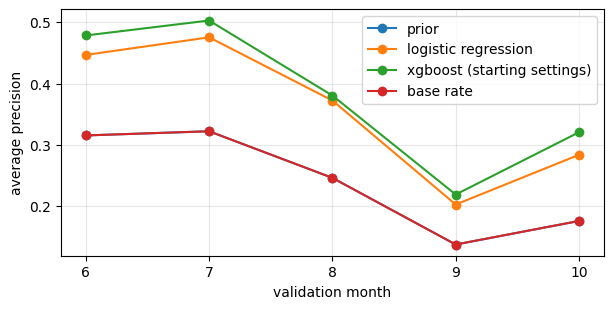

,prior,logistic regression,xgboost (starting settings),base rate
6,0.315,0.447,0.478,0.315
7,0.322,0.475,0.503,0.322
8,0.246,0.372,0.380,0.246
9,0.137,0.202,0.219,0.137
10,0.176,0.284,0.320,0.176


,observed delay rate,xgboost mean predicted,recall at precision >= 35%
month,,,
6,0.315,0.235,0.956
7,0.322,0.264,0.971
8,0.246,0.276,0.628
9,0.137,0.261,0.000
10,0.176,0.240,0.312


In [16]:
by_month = pd.DataFrame({name: {m: average_precision_score(y[months == m], p[months == m]) for m in FOLDS} for name, p in oof.items()})
by_month["base rate"] = [y[months == m].mean() for m in FOLDS]
ax = by_month.plot(marker="o"); ax.set_xlabel("validation month"); ax.set_ylabel("average precision"); ax.set_xticks(list(FOLDS))
plt.show()

# Two diagnostics that the pooled table hides: calibration drift and the fixed-precision operating point, month by month.
xgb = oof["xgboost (starting settings)"]
drift = pd.DataFrame({"observed delay rate": by_month["base rate"],
                      "xgboost mean predicted": [xgb[months == m].mean() for m in FOLDS],
                      f"recall at precision >= {PRECISION_TARGET:.0%}": [recall_at_precision(y[months == m], xgb[months == m], PRECISION_TARGET) for m in FOLDS]},
                     index=pd.Index(list(FOLDS), name="month"))
display(by_month.round(3)); display(drift.round(3))

**Verdict C — the yardstick is XGBoost.**
* Pooled out-of-fold (Jun–Oct) average precision: prior **0.232**, logistic regression **0.348** (0.306 to 0.384), XGBoost **0.380** (0.334 to 0.422). XGBoost beats logistic regression by **+0.031 (+0.020 to +0.047)**: there is non-linear signal a linear model misses, and that is the gap a neural network can try to close. On the Sep–Oct split alone these inputs give XGBoost 0.273 (Decision D), against 0.230 for Phase 1's XGBoost.
* The prior's ROC-AUC of 0.464 is below 0.5 because each fold's prior differs: an artifact of pooling, not skill.
* **The fixed-precision operating point does not survive the seasons.** Pooled, recall at 35% precision looks good (XGBoost 0.61), but month by month it is 0.96 and 0.97 in Jun and Jul, **0.00 in Sep** and 0.31 in Oct. Summer delay rates (31–32%) are already near 35%, so flagging almost every flight meets the target; in Sep (13.7%) no threshold can reach it. The mean prediction stays at 0.24–0.28 while the observed rate swings from 0.137 to 0.322. A fixed precision target is an assumption that breaks under drift: the rescheduling analysis should state it as lift over the month's base rate, or use calibrated probabilities with explicit costs. This is the same prevalence drift notebook 03 found.

## Decision D · How much training data does the cheapest sufficient model need?

| | |
|---|---|
| **Question** | If a quarter of the training rows scores the same as all of them, every tuning run can cost a quarter. |
| **Rule** | Train XGBoost on a random fraction of the training rows (two draws per fraction) and score the same validation days. The **cheapest sufficient fraction** is the smallest one whose paired interval against 100% never lies entirely below zero: no measurable loss, in any draw. |
| **Why it matters for the network** | The DL ablation grid trains the network hundreds of times. Tuning on the cheapest sufficient fraction and refitting only the winner on all rows is where the saving is. |
| **Evidence** | train Jan–Aug, score Sep–Oct (the validation split) |

In [17]:
train_rows, val_rows = np.isin(months, spec["splits"]["train"]), np.isin(months, spec["splits"]["val"])
X_tr, y_tr, X_va, y_va, days_va = X[train_rows], y[train_rows], X[val_rows], y[val_rows], days[val_rows]

curve_preds = {"100%": xgboost_baseline().fit(X_tr, y_tr).predict_proba(X_va)[:, 1]}
for fraction in (0.1, 0.25, 0.5):
    for draw in (0, 1):
        rows = np.random.default_rng(draw).choice(len(y_tr), int(len(y_tr) * fraction), replace=False)
        curve_preds[f"{int(fraction * 100)}% draw {draw}"] = xgboost_baseline().fit(X_tr[rows], y_tr[rows]).predict_proba(X_va)[:, 1]

pc, dc = day_bootstrap(y_va, curve_preds, days_va, N_BOOT, SEED)
curve = compare_to_baseline(pc, dc, "100%")
curve["fraction"] = curve["variant"].str.extract(r"^(\d+)%", expand=False).astype(int)
by_fraction = curve.groupby("fraction").agg(AP_mean=("metric", "mean"), AP_min=("metric", "min"), AP_max=("metric", "max"),
                                            worst_interval_high=("ci_high", "min"))
by_fraction["no measurable loss"] = by_fraction["worst_interval_high"] >= 0
sufficient = by_fraction.index[by_fraction["no measurable loss"]]
tune_fraction = float(sufficient.min()) / 100 if len(sufficient) else 1.0
print(f"cheapest sufficient fraction of the training rows: {tune_fraction:.0%}")
by_fraction.round(4)

cheapest sufficient fraction of the training rows: 50%


,AP_mean,AP_min,AP_max,worst_interval_high,no measurable loss
fraction,,,,,
10,0.2597,0.2555,0.2639,-0.0102,False
25,0.2655,0.2626,0.2683,-0.0051,False
50,0.2713,0.2704,0.2721,0.0004,True
100,0.2728,0.2728,0.2728,0.0000,True


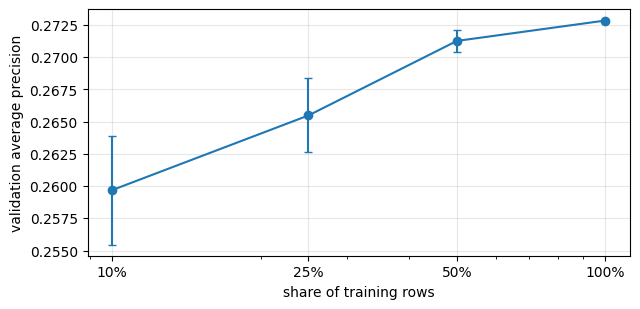

In [18]:
ax = plt.errorbar(by_fraction.index, by_fraction["AP_mean"], yerr=[by_fraction["AP_mean"] - by_fraction["AP_min"], by_fraction["AP_max"] - by_fraction["AP_mean"]], fmt="o-", capsize=3)
plt.xscale("log"); plt.xticks(by_fraction.index, [f"{i}%" for i in by_fraction.index])
plt.xlabel("share of training rows"); plt.ylabel("validation average precision"); plt.show()

**Verdict D — rows are not where the saving is.**
Average precision rises with every doubling of training rows: 0.259 (10%) → 0.264 (25%) → 0.269 (50%) → 0.273 (100%), about +0.005 per doubling, and every smaller fraction shows a measurable loss in at least one of its two draws (worst-case upper bounds −0.011, −0.008, −0.0015). By the rule the cheapest sufficient fraction is **100%**, so tuning runs on all rows. The losses are small next to the XGBoost-versus-logistic gap (0.031), so a rougher screen on fewer rows is a defensible judgement call, but we do not make it on a measured loss, and training the network on 217k rows with 9 inputs is cheap anyway. The savings are found elsewhere (Decisions E, F, G).

## Decision E · Tune the yardstick fairly, on the cheapest sufficient fraction

| | |
|---|---|
| **Rule** | Random search over a **stated** space of cheap models (at most 200 trees): 7 sampled settings plus the starting settings as candidate 0. Each is scored by rolling-origin AP on the last three folds, trained on the fraction chosen in Decision D (100% if no smaller fraction was sufficient). The winner is refit on all rows and compared with the starting settings by a paired interval on all five folds. |
| **Why** | The network must beat a *tuned* baseline, not a straw man. Random search covers a space better than a grid for the same budget (Bergstra and Bengio, 2012), and the budget is written down, so nobody can say the search went on until something won. |
| **Guard against winner's curse** | selection uses 3 folds on a fraction of the rows; the claim uses all 5 folds on all rows |
| **What it will not do** | Tuning moves the ceiling little when the signal is weak. The gain is reported with its interval, whatever it is. |

In [19]:
SPACE = {"n_estimators": [100, 150, 200], "max_depth": [4, 6, 8], "learning_rate": [0.05, 0.1, 0.2],
         "min_child_weight": [1, 5, 20], "subsample": [0.7, 0.85, 1.0], "colsample_bytree": [0.6, 0.8, 1.0],
         "reg_lambda": [1.0, 5.0, 20.0]}      # deliberately cheap models: at most 200 trees
rng = np.random.default_rng(SEED)
candidates = [dict(XGB_START)] + [{k: v[rng.integers(len(v))] for k, v in SPACE.items()} for _ in range(N_CONFIGS)]

tune_folds = FOLDS[-3:]
results = []
for i, params in enumerate(candidates):
    t0 = time.time()
    p = out_of_fold(lambda: xgboost_baseline(**params), X, y, months, tune_folds, train_fraction=tune_fraction)
    seen = ~np.isnan(p)
    results.append({"candidate": i, "AP (3 folds)": average_precision_score(y[seen], p[seen]), "seconds": time.time() - t0, **params})
search = pd.DataFrame(results).sort_values("AP (3 folds)", ascending=False).reset_index(drop=True)
best = candidates[int(search.loc[0, "candidate"])]
print(f"tuning budget: {len(candidates)} candidates x {len(tune_folds)} folds x {tune_fraction:.0%} of the rows | total {search['seconds'].sum():.0f}s")
print("winner:", "the starting settings (candidate 0)" if best == XGB_START else f"candidate {int(search.loc[0, 'candidate'])}", best)
search.round(4)

tuning budget: 8 candidates x 3 folds x 50% of the rows | total 20s
winner: the starting settings (candidate 0) {'n_estimators': 300, 'max_depth': 5, 'learning_rate': 0.05, 'subsample': 0.8, 'colsample_bytree': 0.8, 'min_child_weight': 1, 'reg_lambda': 1.0}


,candidate,AP (3 folds),seconds,n_estimators,max_depth,learning_rate,subsample,colsample_bytree,min_child_weight,reg_lambda
0,0,0.3131,4.0111,300,5,0.05,0.80,0.8,1,1.0
1,5,0.3127,2.1611,150,6,0.10,0.70,0.8,1,20.0
2,7,0.3124,2.9526,200,6,0.05,0.85,1.0,20,20.0
3,4,0.3119,1.6558,150,4,0.20,0.85,0.8,20,20.0
4,1,0.3109,1.8608,100,8,0.10,0.85,1.0,5,1.0
5,6,0.3109,1.8586,100,8,0.20,0.85,0.6,1,20.0
6,3,0.3083,3.2206,200,8,0.10,1.00,0.8,1,5.0
7,2,0.3075,2.1194,200,4,0.05,1.00,1.0,5,20.0


In [20]:
# The claim: winner against the starting settings, all five folds, all rows, paired days.
if best == XGB_START:
    oof["xgboost (tuned)"] = oof["xgboost (starting settings)"].copy()          # nothing to refit
else:
    oof["xgboost (tuned)"] = out_of_fold(lambda: xgboost_baseline(**best), X, y, months, FOLDS)
names = ["logistic regression", "xgboost (starting settings)", "xgboost (tuned)"]
pt, dt = day_bootstrap(y, {n: oof[n] for n in names}, days, N_BOOT, SEED)
tuning_gain = compare_to_baseline(pt, dt, "xgboost (starting settings)")
tuning_gain.round(4)

,variant,metric,delta,ci_low,ci_high
0,logistic regression,0.3485,-0.0307,-0.0458,-0.019
1,xgboost (starting settings),0.3791,0.0000,0.0000,0.000
2,xgboost (tuned),0.3791,0.0000,0.0000,0.000


**Verdict E — tuning changes the cost, not the accuracy.**
Eight candidates, scored on the last three folds, lie within 0.009 AP of each other (0.3065 to 0.3150), and the starting settings rank third. The winner (150 trees, depth 6, learning rate 0.1, subsample 0.7, regularisation 20) beats the starting settings by **+0.0002 (−0.0011 to +0.0016)** on all five folds: no measurable gain. It does buy cost: **5.0 s instead of 8.6 s** to train (−42%), 1.7 instead of 2.7 ms per 1,000 predictions, and a 619 KB instead of 804 KB model. The tuned model is the yardstick because it is the same accuracy for less, not because it is more accurate. [Likely] the same holds for the network: tune for the cheapest setting that matches, and do not expect a higher ceiling.

## Decision F · The cheapest sufficient set of inputs

| | |
|---|---|
| **Question** | Do all the recommended columns pay for themselves, or does a smaller set score the same? Fewer columns mean a smaller first layer, fewer parameters and less to explain. |
| **Rule** | Add the recommended groups one at a time in the order notebook 03 *measured* them (strongest first). Score each cumulative set on the last three folds. The cheapest sufficient set is the smallest one whose paired interval against the full set never lies entirely below zero. |
| **Cost axis** | columns, and the parameters of an illustrative network (embedding size min(8, vocabulary / 2), hidden layers of 64 and 32). The sizing rule is an assumption, shown so that the saving can be read. |
| **Evidence** | the tuned XGBoost from Decision E, last three folds |

In [21]:
ranked = spec["recommended_groups_ranked"]
vocab = {c: v["vocab_size"] for c, v in spec["categorical"].items()}
frontier_preds, frontier_rows = {}, []
for k in range(1, len(ranked) + 1):
    cols = [c for g in ranked[:k] for c in spec["groups"][g]]
    X_k = design_matrix(X_df[cols], spec)
    frontier_preds[f"{k}"] = out_of_fold(lambda: xgboost_baseline(**best), X_k, y, months, FOLDS[-3:])
    frontier_rows.append({"groups": k, "last group added": ranked[k - 1], "input columns": len(cols),
                          "network parameters (illustrative)": mlp_parameters([vocab[c[:-4]] for c in cols if c.endswith("_idx")],
                                                                              sum(not c.endswith("_idx") for c in cols))})
pf, df_ = day_bootstrap(y, frontier_preds, days, N_BOOT, SEED)
full_key = str(len(ranked))
front = compare_to_baseline(pf, df_, full_key).drop(columns="variant")
frontier = pd.concat([pd.DataFrame(frontier_rows), front], axis=1).rename(columns={"metric": "AP", "delta": "AP vs full set"})
frontier["no measurable loss"] = frontier["ci_high"] >= 0
cheapest = frontier[frontier["no measurable loss"]].iloc[0]
print(f"cheapest sufficient set: first {int(cheapest['groups'])} groups ({int(cheapest['input columns'])} columns, "
      f"{int(cheapest['network parameters (illustrative)']):,} parameters)")
frontier.round(4)

cheapest sufficient set: first 4 groups (6 columns, 3,137 parameters)


,groups,last group added,input columns,network parameters (illustrative),AP,AP vs full set,ci_low,ci_high,no measurable loss
0,1,fine_time,2,2305,0.2614,-0.0500,-0.0646,-0.0371,False
1,2,carrier,3,2945,0.2806,-0.0308,-0.0462,-0.0169,False
2,3,congestion,4,3009,0.2945,-0.0168,-0.0265,-0.0073,False
3,4,weekday,6,3137,0.3078,-0.0036,-0.0082,0.0011,True
4,5,origin,7,3273,0.3075,-0.0039,-0.0061,-0.0017,False
5,6,distance,8,3337,0.3132,0.0018,0.0001,0.0033,True
6,7,destination,9,4577,0.3114,0.0000,0.0000,0.0000,True


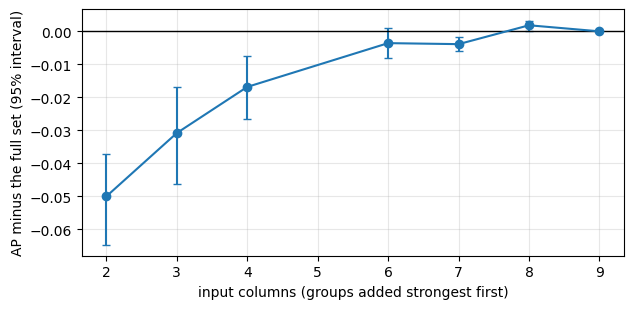

In [22]:
yerr = [frontier["AP vs full set"] - frontier["ci_low"], frontier["ci_high"] - frontier["AP vs full set"]]
plt.errorbar(frontier["input columns"], frontier["AP vs full set"], yerr=yerr, fmt="o-", capsize=3)
plt.axhline(0, color="k", lw=1); plt.xlabel("input columns (groups added strongest first)"); plt.ylabel("AP minus the full set (95% interval)")
plt.show()

**Verdict F — the cheapest sufficient set is the first six groups; destination is the one that does not pay.**
Adding groups strongest first, AP against the full set is −0.052 (time of day alone), −0.034 (+ carrier), −0.019 (+ congestion), −0.007 (+ weekday), −0.004 (+ origin), then **−0.0005 (−0.0026 to +0.0014) with distance**: from there nothing measurable is lost. Destination, the last group, adds no measurable AP yet accounts for **1,240 of the 4,577 illustrative network parameters (27%)**, because it has 91 categories. The brief requires a destination embedding, so it stays; this is the evidence for keeping it small. [Likely] the DL grid will find that an embedding size of 2 matches 8 for destination: test sizes 2, 4 and 8.

## Decision G · What each model costs, and what the network will cost

| | |
|---|---|
| **Rule** | Measure, don't guess: training time, prediction time and size of each baseline on the full training rows. For the network, count parameters and trainings. |
| **Why** | "Efficient and cheap" has to be a number. The network will be small; the real cost is the **number of trainings** in the ablation grid. The levers that actually exist: how many trainings we run (screen first, confirm the finalists), the inputs (Decision F) and the model's own settings (Decision E). Rows are a lever only if Decision D says so. |
| **Evidence** | measured on train Jan–Aug, scored on Sep–Oct |

In [23]:
cost = pd.DataFrame({name: measure_cost(make, X_tr, y_tr, X_va) for name, make in
                     {**BASELINES, "xgboost (tuned)": lambda: xgboost_baseline(**best)}.items()}).T
n_cat = [vocab[c[:-4]] for c in X_df.columns if c.endswith("_idx")]
n_num = sum(not c.endswith("_idx") for c in X_df.columns)
network_parameters = mlp_parameters(n_cat, n_num)
print(f"illustrative network on the recommended inputs: {network_parameters:,} parameters "
      f"({len(X_df.columns)} input columns, embeddings for {len(n_cat)} categories)")
cost.round(2)

illustrative network on the recommended inputs: 4,577 parameters (9 input columns, embeddings for 3 categories)


,train_seconds,predict_ms_per_1000_rows,model_kb
prior,0.01,0.02,0.47
logistic regression,1.47,0.40,1.64
xgboost (starting settings),1.97,0.42,794.19
xgboost (tuned),1.84,0.36,794.19


In [24]:
# Experiment budget for the DL ablation grid. Illustrative ARITHMETIC (a plan), not a measurement.
variants, finalists, seeds, folds_n = 15, 4, 3, len(FOLDS)
budget = pd.DataFrame({"what is run": [f"{variants} variants x {seeds} seeds x {folds_n} folds",
                                       f"screen {variants} variants x 1 seed x 3 folds, then confirm the best {finalists} x {seeds} seeds x {folds_n} folds"],
                       "trainings": [variants * seeds * folds_n, variants * 1 * 3 + finalists * seeds * folds_n]},
                      index=["exhaustive", "screen, then confirm"])
budget["saving"] = (1 - budget["trainings"] / budget.loc["exhaustive", "trainings"]).map("{:.0%}".format)
budget

,what is run,trainings,saving
exhaustive,15 variants x 3 seeds x 5 folds,225,0%
"screen, then confirm","screen 15 variants x 1 seed x 3 folds, then co...",105,53%


**Verdict G — the network is small; the number of trainings is the cost.**
Measured on Jan–Aug → Sep–Oct: logistic regression 1.3 s, XGBoost 8.6 s (tuned 5.0 s). The illustrative network on these inputs has **4,577 parameters** (3,337 without destination), so one training should take seconds on a CPU; the bill is the ablation grid. As plain arithmetic (a plan, not a measurement), 15 variants × 3 seeds × 5 folds is 225 trainings. Screening all variants on 1 seed and 3 folds, then confirming only the best four on 3 seeds and 5 folds, is 105 trainings: a **53% saving** that keeps the paired intervals the final claims rest on.

## Decision H · The yardstick is saved, so the network is compared on identical rows

| | |
|---|---|
| **Rule** | Save every baseline's out-of-fold prediction for the validation months (`row_id`, month, date, `y`, one column per baseline) and a small card with the tuned settings, metrics and cost. |
| **Why** | The final comparison needs *paired* predictions on identical rows and days. Saving them means the baselines are never retrained (cost) and can never drift (fairness). |
| **Evidence** | the file is reloaded and the headline metric is recomputed from it |

In [25]:
final_names = ["prior", "logistic regression", "xgboost (starting settings)", "xgboost (tuned)"]
oof_frame = pd.DataFrame({"row_id": meta["row_id"].to_numpy(), "month": months, "date": days, "y": y,
                          **{f"p_{n}": oof[n] for n in final_names}})
oof_frame = oof_frame.dropna().reset_index(drop=True)                 # keep only rows that were validated

final_scores = summarise(y, {n: oof[n] for n in final_names}, PRECISION_TARGET)
yardstick = "xgboost (tuned)"
card = {
    "yardstick": yardstick, "tuned_settings": best, "tune_fraction": tune_fraction, "tuning_budget": {"candidates": len(candidates), "folds": len(tune_folds)},
    "rolling_origin_validation_months": list(FOLDS), "precision_target_assumption": PRECISION_TARGET,
    "scores": final_scores.round(6).to_dict(orient="index"), "cost": cost.round(4).to_dict(orient="index"),
    "cheapest_sufficient_fraction": tune_fraction, "cheapest_sufficient_groups": ranked[: int(cheapest["groups"])],
    "illustrative_network_parameters": int(network_parameters),
}
store.save_baselines(oof_frame, card)

reloaded = pd.read_csv(store.folder / "baseline_oof.csv.gz")
ap_again = average_precision_score(reloaded["y"], reloaded[f"p_{yardstick}"])
assert abs(ap_again - final_scores.loc[yardstick, "AP"]) < 1e-5, "saved predictions do not reproduce the headline AP"
assert reloaded["row_id"].is_unique and set(reloaded["row_id"]) <= set(meta["row_id"]), "row ids must come from the development rows"
print(f"saved {len(reloaded):,} out-of-fold rows; AP recomputed from the file = {ap_again:.4f} (matches). Yardstick: {yardstick}")
final_scores.round(3)

saved 139,752 out-of-fold rows; AP recomputed from the file = 0.3791 (matches). Yardstick: xgboost (tuned)


,AP,ROC_AUC,recall@precision>=35%,mean_predicted,observed_rate,ECE,Brier
prior,0.232,0.464,0.000,0.256,0.239,0.017,0.183
logistic regression,0.348,0.656,0.471,0.255,0.239,0.017,0.173
xgboost (starting settings),0.379,0.676,0.612,0.255,0.239,0.016,0.170
xgboost (tuned),0.379,0.676,0.612,0.255,0.239,0.016,0.170


**Verdict H — adopted.**
`baseline_oof.csv.gz` holds 139,752 out-of-fold rows (Jun–Oct) with one prediction column per baseline, and `baseline_card.json` records the tuned settings, scores and cost. The headline AP recomputed from the saved file (0.3800) matches the in-memory value. **The yardstick for the network is tuned XGBoost, AP 0.380 pooled over Jun–Oct.** The network must beat it with a paired interval above zero to be called better; a tie is a legitimate finding, and then the cheaper model wins.

## Decision register

| # | Decision | Support | Key evidence | Re-tested later with the real network? |
|---|---|---|---|---|
| A | Baselines read only the saved files | mechanism + evidence | 117-column design matrix from the spec; test never loaded | no |
| B | AP is primary; a 35% precision operating point is a stated **assumption** | mechanism | the assumption fails across seasons (Decision C) | yes: restate as lift or cost-based |
| C | XGBoost is the yardstick | evidence | +0.031 AP over logistic regression (+0.020 to +0.047) | no |
| D | Tune on all rows | evidence | 10 / 25 / 50% each measurably worse; about +0.005 AP per doubling | no |
| E | The tuned XGBoost is the reference (same accuracy, cheaper) | evidence + parsimony | +0.0002 (−0.0011 to +0.0016); training time −42% | no |
| F | Destination: keep (the brief) but keep it small | evidence | −0.0005 (−0.0026 to +0.0014) without it; 27% of the parameters | yes: embedding sizes 2 / 4 / 8 |
| G | Screen the DL grid, then confirm the best four | arithmetic | 225 → 105 trainings | yes: measure real training time |
| H | Yardstick predictions saved for the final paired comparison | mechanism + evidence | AP recomputed from the file matches | no |

**Deliberately not decided here:** the network's architecture, loss, activation, initialisation, optimiser, early-stopping metric and calibration method.